# PID regulation when the actuator saturates

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/blob/main/laboratories/09-pid-saturation/notebook.ipynb)

## Goal
A normalized position plant obeys $\ddot x+2\dot x+x=u$. Match ideal PID gains to poles $-2,-3,-4$. Implement derivative action on measured position using filter time constant $\tau_f=0.03\,\mathrm{s}$ and constrain $u\in[-2,2]$. Command $r=3$ for six seconds and then $r=0.2$. Compare ordinary integration with back-calculation gain $k_{aw}=8\,\mathrm{s^{-1}}$ and report recovery error over the final six seconds.

**Evidence:** every parameter and dataset is synthetic and was chosen for this original teaching scenario.

## Start from the physical system

![Physical system](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/09-pid-saturation/figures/physical-system.png)

A mass, spring, damper and bounded force actuator physically realize the normalized second-order plant. Force saturation is included; contact, dry friction and travel stops are not.

[Five integrated practice problems](https://github.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/blob/main/laboratories/09-pid-saturation/exercises.pdf) accompany this model.

## Read the system diagram

![System diagram](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/09-pid-saturation/figures/system-diagram.png)

Filtered derivative acts on measurement. Back-calculation sends the actual-minus-requested actuator effort into the integral-state equation.

The diagram is original TikZ artwork; the numerical records below are synthetic.

## Setup
Run the optional installation cell if packages are missing. No private data, supplied PDFs or external model files are required.

In [ ]:
%pip -q install numpy scipy matplotlib control

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import control as ct
from scipy.integrate import solve_ivp
from scipy.optimize import brentq, least_squares
plt.ioff()
plt.rcParams.update({'figure.figsize': (9,4.5), 'font.size': 10, 'axes.grid': True, 'grid.alpha': .25})


## Derive the model
### Ideal pole matching
For an ideal PID $K_p+K_i/s+K_ds$, the closed-loop characteristic polynomial is $s^3+(2+K_d)s^2+(1+K_p)s+K_i$. Matching $(s+2)(s+3)(s+4)=s^3+9s^2+26s+24$ gives

$$
K_p=25,\qquad K_i=24,\qquad K_d=7.
$$

These desired poles describe an ideal linear controller, not the filtered saturated implementation.
### Realizable controller states
Let $z$ be a low-pass filtered position, $\tau_f\dot z=x-z$, and let $I$ denote the integral contribution in actuator units. Define

$$
e=r-x,\quad u_* = K_pe+I-K_d(x-z)/\tau_f,\quad u=\operatorname{clip}(u_*,-2,2).
$$

Derivative action is applied to the measurement, avoiding the ideal derivative impulse from a reference step. The unsaturated characteristic polynomial becomes

$$
\tau_fs^4+(1+2\tau_f)s^3+[2+\tau_f(1+K_p)+K_d]s^2+[1+K_p+K_i\tau_f]s+K_i.
$$

Its roots must be checked separately.
### Windup and back-calculation
Ordinary integration uses $\dot I=K_ie$. Back-calculation uses $\dot I=K_ie+8(u-u_*)$. The second term reduces the mismatch between requested and realizable actuator effort. It vanishes when unsaturated.
The initial command 3 is infeasible because the plant's static gain is one and the actuator limit is 2. The experiment intentionally accumulates windup, then commands a feasible target. Integrate the two time intervals separately so the reference discontinuity is not smoothed by the solver.
### Assessment
Compare the integral state, output, actuator and integral absolute error after the command reduction. Back-calculation improves this particular recovery; its gain is not a universal optimum and noisy measurements or other saturation limits can change the result.

## Compute and check
The first lines declare the scenario parameters. Follow the model construction, run the numerical experiment, and inspect the assertions and printed metrics.

In [2]:
kp,ki,kd,filter_tau=25.,24.,7.,.03
linear_den=[filter_tau,1+2*filter_tau,2+filter_tau*(1+kp)+kd,1+kp+ki*filter_tau,ki]
assert np.max(np.roots(linear_den).real)<0
def dynamics(reference,antiwindup):
    def derivative(t,state):
        position,velocity,integral,filtered=state
        error=reference-position
        request=kp*error+integral-kd*(position-filtered)/filter_tau
        effort=np.clip(request,-2,2)
        return [velocity,effort-2*velocity-position,ki*error+antiwindup*(effort-request),(position-filtered)/filter_tau]
    return derivative
cases=[]; recovery=[]
for antiwindup in [0.,8.]:
    first=solve_ivp(dynamics(3.,antiwindup),[0,6],np.zeros(4),t_eval=np.linspace(0,6,3001),rtol=1e-8,atol=1e-10,max_step=.01)
    second=solve_ivp(dynamics(.2,antiwindup),[6,12],first.y[:,-1],t_eval=np.linspace(6,12,3001),rtol=1e-8,atol=1e-10,max_step=.01)
    time=np.r_[first.t,second.t[1:]]; states=np.c_[first.y,second.y[:,1:]]
    reference=np.where(time<6,3.,.2)
    request=kp*(reference-states[0])+states[2]-kd*(states[0]-states[3])/filter_tau
    effort=np.clip(request,-2,2)
    iae=np.trapezoid(np.abs(.2-second.y[0]),second.t)
    recovery.append(iae); cases.append((antiwindup,time,states,effort))
    print(f'Back-calculation gain {antiwindup:g}: recovery IAE={iae:.6f}, final x={states[0,-1]:.6f}')
assert recovery[1] < recovery[0]


Back-calculation gain 0: recovery IAE=9.756216, final x=0.570287


Back-calculation gain 8: recovery IAE=1.841207, final x=0.199941


## Plot the evidence
The figure below displays the computed experiment. Axis units and legends distinguish the model variants; the curves are simulations.

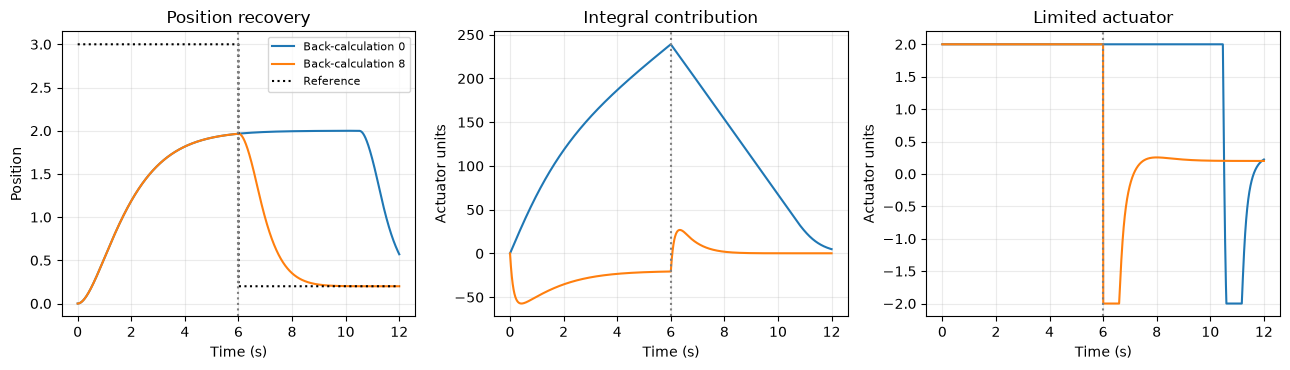

In [3]:
fig,axes=plt.subplots(1,3,figsize=(13,3.8))
for gain,time,states,effort in cases:
    label=f'Back-calculation {gain:g}'
    axes[0].plot(time,states[0],label=label); axes[1].plot(time,states[2],label=label); axes[2].plot(time,effort,label=label)
axes[0].plot(time,np.where(time<6,3.,.2),'k:',label='Reference')
for ax,title,ylabel in zip(axes,['Position recovery','Integral contribution','Limited actuator'],['Position','Actuator units','Actuator units']):
    ax.set(xlabel='Time (s)',ylabel=ylabel,title=title); ax.axvline(6,color='gray',ls=':')
axes[0].legend(fontsize=8); fig.tight_layout()

plt.show()

## Interpret and extend
An infeasible command cannot be repaired by controller gain. Anti-windup improves recovery after saturation rather than increasing physical actuator capacity.

Change one parameter at a time, predict the direction of its effect from the equations, and rerun all cells. Explain any discrepancy before accepting a revised conclusion.

## References
- [APMonitor Dynamics and Control](https://apmonitor.com/pdc/)
- [Feedback Systems, open textbook](https://fbsbook.org/)
- [Python Control documentation](https://python-control.readthedocs.io/en/0.10.2/)
- [Worked PDF report](report.pdf)